In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

In [ ]:
data=pd.read_csv("Case C.csv")

In [ ]:
data

,X,Y
0,1,1
1,2,4
2,3,9
3,4,16
4,5,25
5,6,36
6,7,49
7,8,64
8,9,81


In [ ]:
X = data["X"]
y = data["Y"]


In [ ]:
X_train = X.iloc[:5]
y_train = y.iloc[:5]

# Validation: records 6–7
X_val = X.iloc[5:7]
y_val = y.iloc[5:7]

# Testing: records 8–9
X_test = X.iloc[7:9]
y_test = y.iloc[7:9]

In [ ]:
linear_model = LinearRegression()
linear_model.fit(X_train.values.reshape(-1, 1), y_train)
linear_val = linear_model.predict(X_val.values.reshape(-1, 1))
linear_test = linear_model.predict(X_test.values.reshape(-1, 1))


In [ ]:
linear_val_mse = mean_squared_error(y_val, linear_val)
linear_test_mse = mean_squared_error(y_test, linear_test)
print(linear_val_mse)
print(linear_test_mse)

122.50000000000003
842.5


In [ ]:
polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
polynomial_model.fit(X_train.values.reshape(-1, 1), y_train)
poly_val=polynomial_model.predict(X_val.values.reshape(-1, 1))
poly_test=polynomial_model.predict(X_test.values.reshape(-1, 1))

In [ ]:
poly_val_mse = mean_squared_error(y_val, poly_val)
poly_test_mse = mean_squared_error(y_test, poly_test)
print(poly_val_mse)
print(poly_test_mse)

2.524354896707238e-29
5.048709793414476e-28


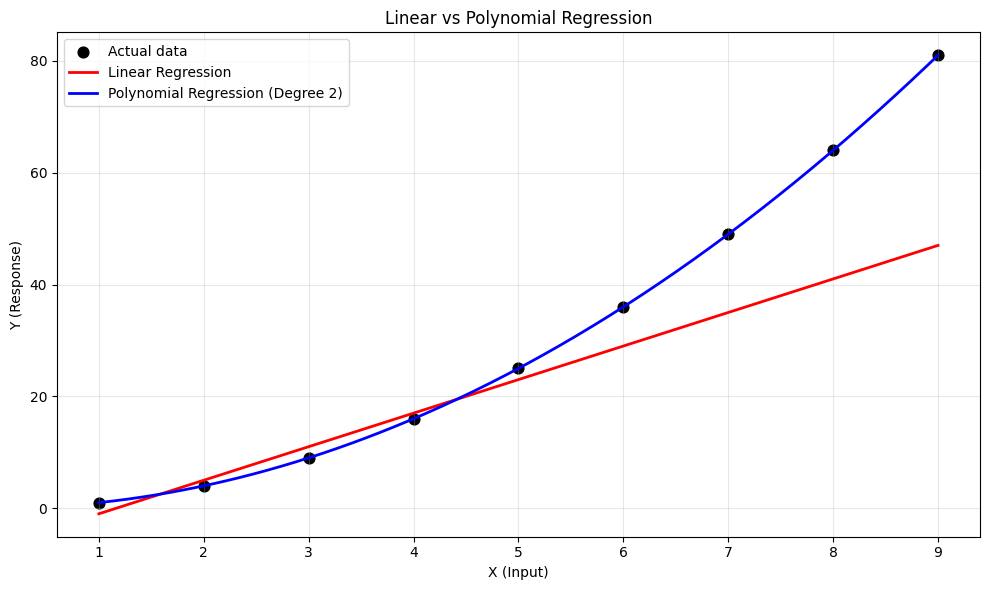

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Generate smooth X values for the curves
X_curve = np.linspace(
    data["X"].min(), data["X"].max(), 300
).reshape(-1, 1)

# Predict using both trained models
linear_curve = linear_model.predict(X_curve)
poly_curve = polynomial_model.predict(X_curve)

# Plot the actual dataset
plt.figure(figsize=(10, 6))
plt.scatter(data["X"], data["Y"],
            color="black", s=60, label="Actual data")

# Plot Linear Regression
plt.plot(X_curve, linear_curve,
         color="red", linewidth=2,
         label="Linear Regression")

# Plot Polynomial Regression
plt.plot(X_curve, poly_curve,
         color="blue", linewidth=2,
         label="Polynomial Regression (Degree 2)")

# Add labels and formatting
plt.xlabel("X (Input)")
plt.ylabel("Y (Response)")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
